In [1]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths
from matplotlib.patches import PathPatch

In [2]:
df = pd.read_csv('RatioHalves_merged.csv')
df = df.drop('Cups Hab', 1)
print(df.loc[df['Control']=='y',:])

    Group  Cups LTM       LTM Control
0       1  0.016000  0.100000       y
3       4  0.070000 -0.016000       y
5       6 -0.080000 -0.085333       y
10     11 -0.022667 -0.158000       y
15     16  0.092000  0.018000       y
16     17  0.120667  0.127333       y
17     18 -0.030667  0.108000       y
19     20  0.103333  0.045333       y
23     24  0.012667 -0.069333       y
24     25 -0.088000  0.076000       y
27     28  0.084667 -0.079333       y
28     29  0.138000  0.032667       y
29     30 -0.174000 -0.180000       y
31     32  0.182047  0.060933       y
32     33  0.083333  0.041000       y
33     34  0.024400  0.057667       y
35     36  0.071067 -0.104000       y
36     37 -0.134667 -0.081227       y
37     38 -0.071067  0.120000       y
38     39  0.061204  0.340000       y
39     40 -0.031333  0.041333       y
40     41 -0.039267 -0.122733       y
41     42  0.009333  0.183867       y


In [3]:
data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
#print(newdf)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


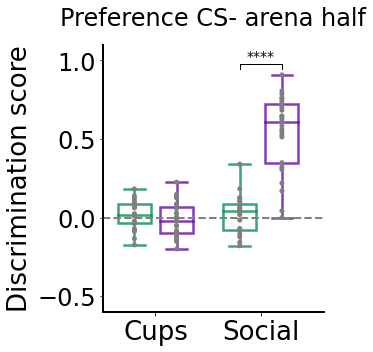

In [4]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}

text_boxplot = ['','****']
colors = ["C7","C7"]
colors_boxplot = ['#078f4f', "#680aab"]

ax = sns.stripplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    palette=colors,
    jitter=0,
    dodge=True
)


locs = ["upper left"]
boxplot = sns.boxplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    palette=colors_boxplot,
    fliersize=0,
    linewidth=2.5,
    **PROPS
)
plt.axhline(linewidth=2, color='grey',ls='--')

data_ratio = 0.4016222222466667

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

#CHANGE BOXPLOT STYLE

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches

for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[i%2]
    patch.set_edgecolor(col)
    patch.set_facecolor('None')
    
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        
        
#END CHANGE BOXPLOT STYLE

#handles, labels = ax.get_legend_handles_labels()
#l = plt.legend(handles[0:2], ["", ""],loc=2)
plt.legend([],[], frameon=False)

ax.set_xticklabels(['Cups','Social'], fontsize = 26)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)

#ax.text(-0.3,1.15,'Upper', fontsize = 26)
#ax.text(0.9,1.15,'CS-', fontsize = 26)

ax.set_xlabel("",fontsize=20)
ax.set_ylabel('Discrimination score', fontsize = 26)


ax.set_ylim([-0.5999,1.1])
ax.set_xlim([-0.5,1.6])

#significance(ax,0,data_ratio,newdf.loc[newdf['Experimental Condition']=='Cups LTM']['Left preference'].max(),text=text_boxplot[0])
significance(ax,1,data_ratio,newdf.loc[newdf['Experimental Condition']=='LTM']['Left preference'].max(),text=text_boxplot[1])

plt.title("Preference CS- arena half", fontsize=24,y=1.05)

fig = ax.get_figure()

#adjust_box_widths(fig, 0.7)
#fig.set_size_inches(6.3,5)
adjust_box_widths(fig, 0.8)
fig.set_size_inches(4.7,5)
ax.tick_params(axis='y', which='major', labelsize=24)

plt.tight_layout()
fig.tight_layout()
fig.savefig("Fig_ScoresHalves.jpg",dpi=500,bbox_inches='tight')
plt.savefig('Fig_ScoresHalves.eps', format='eps')

